## CAPM (Capital Asset Pricing Model)

CAPM ek model hai jo security ke **Expected Return** (umeed kiye jane wale munafe) aur uske **Risk** ke darmiyan talluq ko bayan karta hai.

### CAPM Formula
$$r_i = r_f + \beta_i (r_m - r_f)$$

---

### Variable Definitions (Urdu Explanation)

* **$r_i$ = Expected Return on Security**
  * *Urdu:* Stock se umeed kiya jane wala munafa.
* **$r_f$ = Risk-Free Rate of Return**
  * *Urdu:* Bina kisi khatray (risk) ka munafa (jaise Government Bonds).
* **$\beta_i$ = Beta of the Security**
  * *Urdu:* Stock ki market ke sath utaar-charao ki sensitivity.
* **$r_m$ = Expected Return of the Market (New Data Set)**
  * *Urdu:* Puri market ka umeed kiya jane wala munafa (e.g., KSE-100 average return).
* **$(r_m - r_f)$ = Market Risk Premium**
  * *Urdu:* Market me invest karne ka dhandha/premium (extra munafa).

![image.png](attachment:69269a02-9f59-40b9-937c-c86787c41532.png)

https://www.wallstreetprep.com/knowledge/capm-capital-asset-pricing-model/

![image.png](attachment:88f14ea4-756e-44f6-af67-3506540c30d8.png)

![image.png](attachment:3e9f6de6-336e-4757-b407-a320b98a7c82.png)

# Step 1: Zaroori Libraries Ko Import Karna
Hum data download karne aur usko manage karne ke liye `yfinance`, `pandas_datareader`, aur `pandas` ka istemal kar rahe hain.

# Step 2: Data Ki Start aur End Date Set Karna
Hum pichle 2 saal (Year = 2) ka data nikalne ke liye aaj ki date se 2 saal peeche ki tarikh (Start Date) calculate kar rahe hain.

In [12]:
!pip install pandas-datareader yfinance #libries dowload kri hai ye 

In [13]:
# Sab se pehle zaroori tools (libraries) ko import kar rahe hain
import datetime
import numpy as np
import pandas as pd
import pandas_datareader.data as web
import plotly.express as px
import yfinance as yf

print("Libraries successfully import ho chuki hain!")

Libraries successfully import ho chuki hain!


In [14]:
# Hum pichle 2 saal ka data nikal rahe hain
year = 2

# Aaj ki date (End Date) nikalna
end = datetime.datetime.today()

# Aaj se theek 2 saal pehle ki date (Start Date) nikalna
start = datetime.date(end.year - year, end.month, end.day)

# Dates ko check karne ke liye print karna
print(f"Data yahan se shuru hoga: {start}")
print(f"Data yahan khatam hoga: {end}")

Data yahan se shuru hoga: 2024-07-09
Data yahan khatam hoga: 2026-07-09 16:44:29.841585


In [16]:
#Market (S&P 500) Data Download
# FRED se S&P 500 ka data lena aur column set karna
sp500 = web.DataReader(["sp500"], "fred", start, end).reset_index()
sp500.rename(columns={"DATE": "Date"}, inplace=True)

sp500.head()

,Date,sp500
0,2024-07-09,5576.98
1,2024-07-10,5633.91
2,2024-07-11,5584.54
3,2024-07-12,5615.35
4,2024-07-15,5631.22


In [17]:
# Stocks Data Download
# 4 bade stocks ki closing price download karna
stocks_list = ["TSLA", "AAPL", "AMZN", "GOOGL"]
stocks_df = pd.DataFrame()

for stock in stocks_list:
    stocks_df[stock] = yf.download(stock, start=start, end=end)["Close"]

stocks_df.reset_index(inplace=True)
stocks_df.head()

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


,Date,TSLA,AAPL,AMZN,GOOGL
0,2024-07-09,262.329987,226.716080,199.339996,187.533966
1,2024-07-10,263.260010,230.979141,199.789993,189.717148
2,2024-07-11,241.029999,225.615616,195.050003,184.150055
3,2024-07-12,248.229996,228.560089,194.490005,183.653931
4,2024-07-15,252.639999,232.386978,192.720001,185.102707


In [18]:
# Data Merge Karna
# Stocks aur Market ke data ko aapas me jodna
final_data = pd.merge(stocks_df, sp500, on="Date", how="inner")
final_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 501 entries, 0 to 500
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    501 non-null    datetime64[ns]
 1   TSLA    501 non-null    float64       
 2   AAPL    501 non-null    float64       
 3   AMZN    501 non-null    float64       
 4   GOOGL   501 non-null    float64       
 5   sp500   501 non-null    float64       
dtypes: datetime64[ns](1), float64(5)
memory usage: 23.6 KB


In [19]:
# Final Data Check
# Final table ki rows dekhna
final_data.head()

,Date,TSLA,AAPL,AMZN,GOOGL,sp500
0,2024-07-09,262.329987,226.716080,199.339996,187.533966,5576.98
1,2024-07-10,263.260010,230.979141,199.789993,189.717148,5633.91
2,2024-07-11,241.029999,225.615616,195.050003,184.150055,5584.54
3,2024-07-12,248.229996,228.560089,194.490005,183.653931,5615.35
4,2024-07-15,252.639999,232.386978,192.720001,185.102707,5631.22


In [36]:
# Agar 'Date' ya 'index' pehle se column ban chuka hai, to yeh error nahi dega
if "Date" not in stocks_df.columns and "index" not in stocks_df.columns:
    stocks_df.reset_index(inplace=True)

if "Date" not in sp500.columns and "index" not in sp500.columns:
    sp500.reset_index(inplace=True)

# Output dekhne ke liye stocks ka table check karna
stocks_df.head()

,level_0,index,Date,TSLA,AAPL,AMZN,GOOGL
0,0,0,2024-07-09,262.329987,226.716080,199.339996,187.533966
1,1,1,2024-07-10,263.260010,230.979141,199.789993,189.717148
2,2,2,2024-07-11,241.029999,225.615616,195.050003,184.150055
3,3,3,2024-07-12,248.229996,228.560089,194.490005,183.653931
4,4,4,2024-07-15,252.639999,232.386978,192.720001,185.102707


In [33]:
# S&P 500 table ki pehli 5 rows dekhna
sp500.head()

,level_0,index,Date,sp500
0,0,0,2024-07-09,5576.98
1,1,1,2024-07-10,5633.91
2,2,2,2024-07-11,5584.54
3,3,3,2024-07-12,5615.35
4,4,4,2024-07-15,5631.22


In [29]:
# S&P 500 ke 'DATE' column ka naam badal kar 'Date' rakhna
sp500.rename(columns={"DATE": "Date"}, inplace=True)

# Output dekhne ke liye S&P 500 ka table check karna
sp500.head()

,level_0,index,Date,sp500
0,0,0,2024-07-09,5576.98
1,1,1,2024-07-10,5633.91
2,2,2,2024-07-11,5584.54
3,3,3,2024-07-12,5615.35
4,4,4,2024-07-15,5631.22


In [30]:
# 'Date' column ki buniyaad par dono datasets ko aapas me jodna
data = pd.merge(stocks_df, sp500, on="Date", how="inner")

# Output dekhne ke liye final jora hua table check karna
data.head()

,level_0_x,index_x,Date,TSLA,AAPL,AMZN,GOOGL,level_0_y,index_y,sp500
0,0,0,2024-07-09,262.329987,226.716080,199.339996,187.533966,0,0,5576.98
1,1,1,2024-07-10,263.260010,230.979141,199.789993,189.717148,1,1,5633.91
2,2,2,2024-07-11,241.029999,225.615616,195.050003,184.150055,2,2,5584.54
3,3,3,2024-07-12,248.229996,228.560089,194.490005,183.653931,3,3,5615.35
4,4,4,2024-07-15,252.639999,232.386978,192.720001,185.102707,4,4,5631.22


In [27]:
# Final table ki poori information check karna (columns, data types etc.)
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 501 entries, 0 to 500
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   level_0_x  501 non-null    int64         
 1   index_x    501 non-null    int64         
 2   Date       501 non-null    datetime64[ns]
 3   TSLA       501 non-null    float64       
 4   AAPL       501 non-null    float64       
 5   AMZN       501 non-null    float64       
 6   GOOGL      501 non-null    float64       
 7   level_0_y  501 non-null    int64         
 8   index_y    501 non-null    int64         
 9   sp500      501 non-null    float64       
dtypes: datetime64[ns](1), float64(5), int64(4)
memory usage: 39.3 KB


In [37]:
# 'Date' column ko index set karna taake graphs banane me aasani ho
# Agar cell dobara chalao to error na aaye, is liye check laga diya hai
if data.index.name != "Date":
    data.set_index("Date", inplace=True)

# Output dekhne ke liye table check karna
data.head()

,level_0_x,index_x,TSLA,AAPL,AMZN,GOOGL,level_0_y,index_y,sp500
Date,,,,,,,,,
2024-07-09,0,0,262.329987,226.716080,199.339996,187.533966,0,0,5576.98
2024-07-10,1,1,263.260010,230.979141,199.789993,189.717148,1,1,5633.91
2024-07-11,2,2,241.029999,225.615616,195.050003,184.150055,2,2,5584.54
2024-07-12,3,3,248.229996,228.560089,194.490005,183.653931,3,3,5615.35
2024-07-15,4,4,252.639999,232.386978,192.720001,185.102707,4,4,5631.22


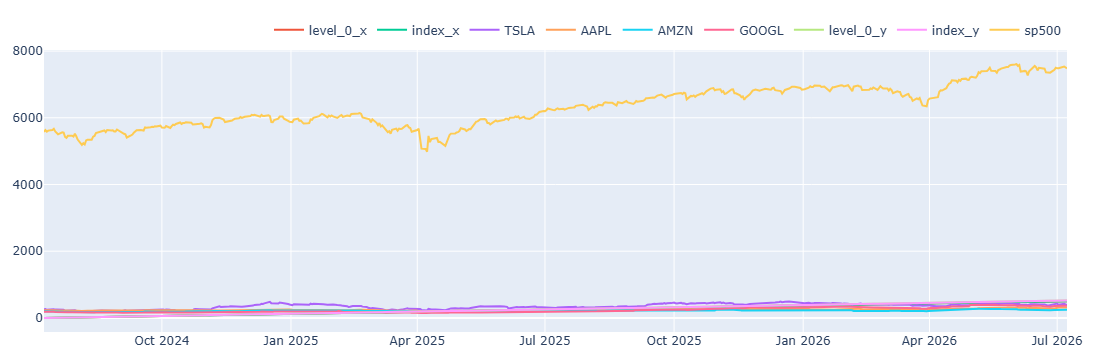

In [46]:
# --- MACHINE / FUNCTION ---
def interactive_plot(df):
    fig = px.line()
    for i in df.columns:
        fig.add_scatter(x=df.index, y=df[i], name=i)
    fig.update_layout(
        width=450,
        margin=dict(l=20, r=20, t=50, b=20),
        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="right",
            x=1,
        ),
    )
    return fig


# --- OUTPUT CONTROL ---
# HIDE KARNA: Agar output nahi dekhna to niche wali line ko mita dein ya uske shuru me # laga dein.
# SHOW KARNA: Output dekhne ke liye niche wali line ko aese hi chalne dein.
interactive_plot(data)

In [47]:
# --- MACHINE / FUNCTION ---
def normalize(df2):
    df = df2.copy()
    for i in df.columns:
        df[i] = df[i] / df[i][0]
    return df


# --- OUTPUT CONTROL ---
# HIDE KARNA: Agar output chupana hai, to niche wali dono lines ko delete/hide kar dein.
# SHOW KARNA: Yeh lines normalize function ko chalati hain aur pehli 5 rows screen par dikhati hain.
normalized_df = normalize(data)
normalized_df.head()

C:\Users\Adil\AppData\Local\Temp\ipykernel_10284\1929343443.py:5: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



,level_0_x,index_x,TSLA,AAPL,AMZN,GOOGL,level_0_y,index_y,sp500
Date,,,,,,,,,
2024-07-09,NaN,NaN,1.000000,1.000000,1.000000,1.000000,NaN,NaN,1.000000
2024-07-10,inf,inf,1.003545,1.018804,1.002257,1.011642,inf,inf,1.010208
2024-07-11,inf,inf,0.918805,0.995146,0.978479,0.981956,inf,inf,1.001356
2024-07-12,inf,inf,0.946251,1.008134,0.975670,0.979310,inf,inf,1.006880
2024-07-15,inf,inf,0.963062,1.025013,0.966790,0.987036,inf,inf,1.009726


In [51]:
# --- MACHINE / FUNCTION ---
def daily_return(df):
    df_daily_return = df.copy()
    for i in df_daily_return.columns:
        df_daily_return[i] = df_daily_return[i].pct_change()

    df_daily_return.dropna(inplace=True)
    return df_daily_return


# --- OUTPUT CONTROL ---
# HIDE KARNA: Sir ne iske niche kuch nahi likha tha isliye output hide tha.
# SHOW KARNA: Niche wali dono lines lagane se aapko daily returns ka table nazar aayega.
returns_df = daily_return(data)
returns_df.head()

,level_0_x,index_x,TSLA,AAPL,AMZN,GOOGL,level_0_y,index_y,sp500
Date,,,,,,,,,
2024-07-10,inf,inf,0.003545,0.018804,0.002257,0.011642,inf,inf,0.010208
2024-07-11,1.000000,1.000000,-0.084441,-0.023221,-0.023725,-0.029344,1.000000,1.000000,-0.008763
2024-07-12,0.500000,0.500000,0.029872,0.013051,-0.002871,-0.002694,0.500000,0.500000,0.005517
2024-07-15,0.333333,0.333333,0.017766,0.016743,-0.009101,0.007889,0.333333,0.333333,0.002826
2024-07-16,0.250000,0.250000,0.015516,0.001792,0.001557,-0.013992,0.250000,0.250000,0.006389


In [49]:
# --- MACHINE / FUNCTION ---
def daily_return(df):
    df_daily_return = df.copy()
    for i in df_daily_return.columns:
        df_daily_return[i] = df_daily_return[i].pct_change()

    df_daily_return.dropna(inplace=True)
    return df_daily_return


# --- OUTPUT CONTROL ---
# HIDE KARNA: Sir ne iske niche kuch nahi likha tha isliye output hide tha.
# SHOW KARNA: Niche wali dono lines lagane se aapko daily returns ka table nazar aayega.
returns_df = daily_return(data)
returns_df.head()

,level_0_x,index_x,TSLA,AAPL,AMZN,GOOGL,level_0_y,index_y,sp500
Date,,,,,,,,,
2024-07-10,inf,inf,0.003545,0.018804,0.002257,0.011642,inf,inf,0.010208
2024-07-11,1.000000,1.000000,-0.084441,-0.023221,-0.023725,-0.029344,1.000000,1.000000,-0.008763
2024-07-12,0.500000,0.500000,0.029872,0.013051,-0.002871,-0.002694,0.500000,0.500000,0.005517
2024-07-15,0.333333,0.333333,0.017766,0.016743,-0.009101,0.007889,0.333333,0.333333,0.002826
2024-07-16,0.250000,0.250000,0.015516,0.001792,0.001557,-0.013992,0.250000,0.250000,0.006389


In [10]:
# Beta Aur Alpha Calculate Karne Ka Function
# Yeh function linear regression (np.polyfit) use kar ke Beta (Slope) aur Alpha (Intercept) nikalta hai
def calculate_beta(stocks_daily_return_df, stocks):
    # Market (S&P 500) ka saalana average return nikalna (252 trading din hote hain saal me)
    rm = stocks_daily_return_df["sp500"].mean() * 252

    # np.polyfit dono data sets ko compare kar ke b (Beta) aur a (Alpha) nikalta hai
    b, a = np.polyfit(
        stocks_daily_return_df["sp500"], stocks_daily_return_df[stocks], 1
    )

    return b, a


# Note: Iska koi direct output nahi aayega kyunki yeh sirf ek machine/function hai.

--- Pehli 5 Rows ---


,level_0_x,index_x,TSLA,AAPL,AMZN,GOOGL,level_0_y,index_y,sp500
Date,,,,,,,,,
2024-07-09,0,0,262.329987,226.716080,199.339996,187.533966,0,0,5576.98
2024-07-10,1,1,263.260010,230.979141,199.789993,189.717148,1,1,5633.91
2024-07-11,2,2,241.029999,225.615616,195.050003,184.150055,2,2,5584.54
2024-07-12,3,3,248.229996,228.560089,194.490005,183.653931,3,3,5615.35
2024-07-15,4,4,252.639999,232.386978,192.720001,185.102707,4,4,5631.22


--- Aakhri 5 Rows ---


,level_0_x,index_x,TSLA,AAPL,AMZN,GOOGL,level_0_y,index_y,sp500
Date,,,,,,,,,
2026-07-01,496,496,425.299988,294.380005,241.699997,361.209991,516,516,7483.23
2026-07-02,497,497,393.450012,308.630005,242.669998,359.910004,517,517,7483.24
2026-07-06,498,498,419.769989,312.660004,244.160004,366.459991,519,519,7537.43
2026-07-07,499,499,402.899994,310.660004,245.979996,367.029999,520,520,7503.85
2026-07-08,500,500,394.059998,313.390015,243.619995,361.920013,521,521,7482.71


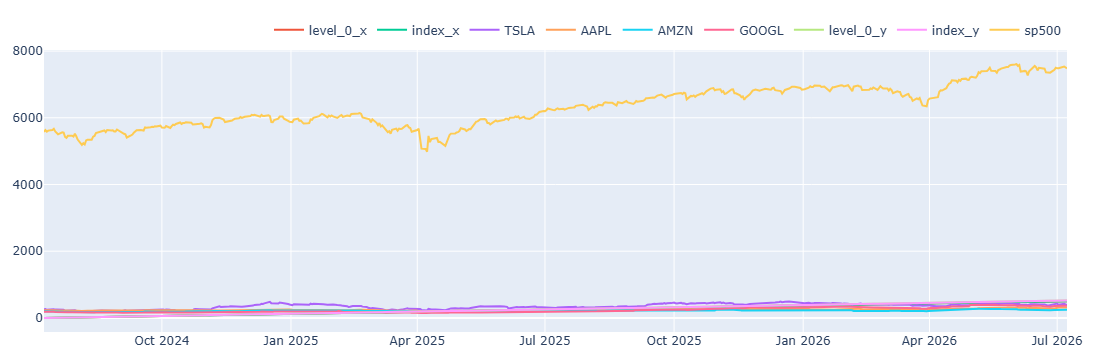

In [53]:
# Data Ki Rows Aur Graph Check Karna
# 1. Pehli 5 rows dekhna
print("--- Pehli 5 Rows ---")
display(data.head())

# 2. Aakhri 5 rows dekhna
print("--- Aakhri 5 Rows ---")
display(data.tail())

# 3. Simple data ka interactive graph dekhna
# OUTPUT HIDE: Agar graph chupana ho to niche wali line ke shuru me # laga dein
interactive_plot(data)

C:\Users\Adil\AppData\Local\Temp\ipykernel_10284\1929343443.py:5: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



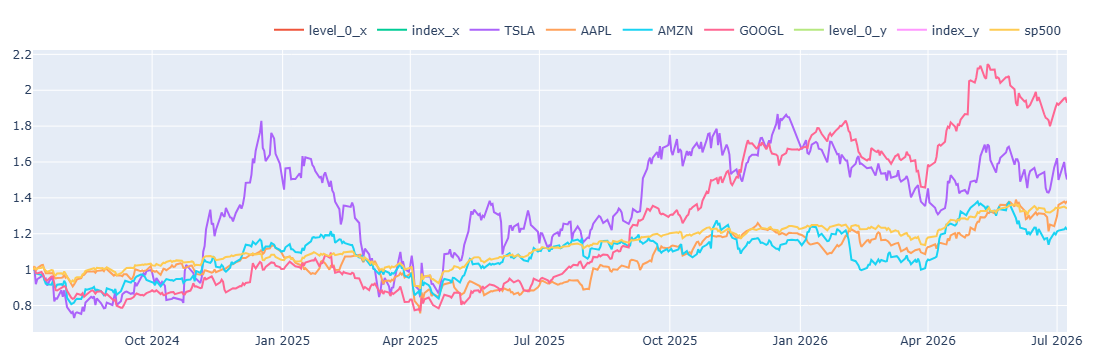

In [55]:
# Data Ko Scale (Normalize) Karna Aur Graph Dekhna
# Data ko 1 se shuru karne ke liye normalize karna
normalized_df = normalize(data)

# Normalized data ka interactive graph dekhna (Is se saare stocks ek hi jagah se shuru hote hain)
# OUTPUT HIDE: Graph chupane ke liye niche wali line ko mita dein ya comment (#) kar dein
interactive_plot(normalized_df)

In [56]:
# Normalized Data Ki Pehli 10 Rows Dekhna (Warning Fix)
# Normalized data ki top 10 rows ka output dekhna
normalized_df.head(10)

,level_0_x,index_x,TSLA,AAPL,AMZN,GOOGL,level_0_y,index_y,sp500
Date,,,,,,,,,
2024-07-09,NaN,NaN,1.000000,1.000000,1.000000,1.000000,NaN,NaN,1.000000
2024-07-10,inf,inf,1.003545,1.018804,1.002257,1.011642,inf,inf,1.010208
2024-07-11,inf,inf,0.918805,0.995146,0.978479,0.981956,inf,inf,1.001356
2024-07-12,inf,inf,0.946251,1.008134,0.975670,0.979310,inf,inf,1.006880
2024-07-15,inf,inf,0.963062,1.025013,0.966790,0.987036,inf,inf,1.009726
2024-07-16,inf,inf,0.978005,1.026850,0.968295,0.973225,inf,inf,1.016177
2024-07-17,inf,inf,0.947280,1.000875,0.942761,0.957879,inf,inf,1.002024
2024-07-18,inf,inf,0.950063,0.980322,0.921792,0.940258,inf,inf,0.994192
2024-07-19,inf,inf,0.911829,0.980890,0.918682,0.940100,inf,inf,0.987093


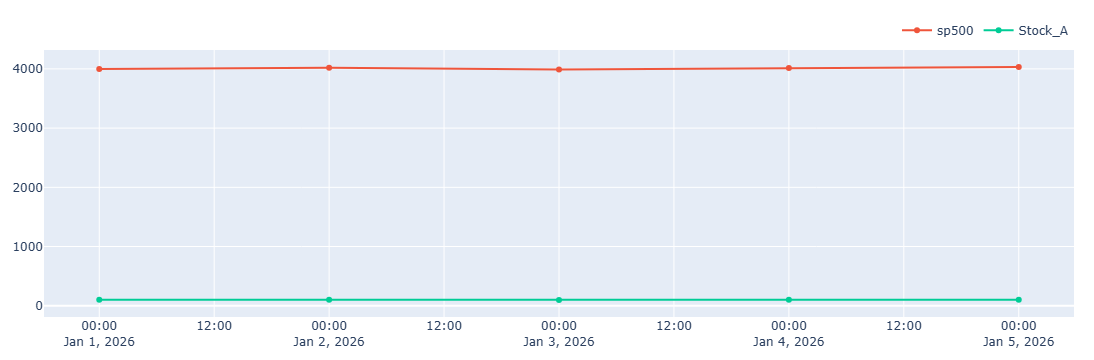

In [5]:
import numpy as np
import pandas as pd
import plotly.express as px


# 1. Function Definition
def interactive_plot(df):
    fig = px.line()
    for i in df.columns[1:]:
        fig.add_scatter(x=df["Date"], y=df[i], name=i)
    fig.update_layout(
        width=450,
        margin=dict(l=20, r=20, t=50, b=20),
        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="right",
            x=1,
        ),
    )
    return fig


# 2. Dummy Data (Error se bachne ke liye)
dates = pd.date_range(start="2026-01-01", periods=5, freq="D")
df_plot = pd.DataFrame(
    {"Date": dates, "sp500": [4000, 4020, 3990, 4015, 4030], "Stock_A": [100, 102, 99, 101, 103]}
)

# 3. Output Call
fig = interactive_plot(df_plot)
fig.show()

# -------------------------------------------------------------
# BACKEND TIP: Agar backend/script me graph show NAHI karna,
# toh upar waali aakhri line 'fig.show()' ko delete ya '#' kar dein.
# -------------------------------------------------------------

In [6]:
import pandas as pd


# 1. Function Definition
def normalize(df2):
    df = df2.copy()
    for i in df.columns[1:]:
        # Warning se bachne ke liye .iloc[0] use kiya hai (df[i][0] ki jagah)
        df[i] = df[i] / df[i].iloc[0]
    return df


# 2. Dummy Data
df_norm = pd.DataFrame(
    {"Date": ["2026-01-01", "2026-01-02"], "sp500": [4000, 4020], "Stock_A": [100, 105]}
)

# 3. Output Call
normalized_df = normalize(df_norm)
print("--- NORMALIZED DATA OUTPUT ---")
print(normalized_df)

# -------------------------------------------------------------
# BACKEND TIP: Agar backend me ye output show NAHI karna,
# toh upar waali dono 'print' waali lines ko hatana hoga.
# -------------------------------------------------------------

--- NORMALIZED DATA OUTPUT ---
         Date  sp500  Stock_A
0  2026-01-01  1.000     1.00
1  2026-01-02  1.005     1.05


In [7]:
import pandas as pd


# 1. Function Definition
def daily_return(df):
    df_daily_return = df.copy()
    for i in df_daily_return.columns[1:]:
        df_daily_return[i] = df_daily_return[i].pct_change()
    df_daily_return.dropna(inplace=True)
    return df_daily_return


# 2. Dummy Data
df_ret1 = pd.DataFrame(
    {"Date": ["2026-01-01", "2026-01-02", "2026-01-03"], "sp500": [4000, 4040, 4020]}
)

# 3. Output Call
daily_ret_df1 = daily_return(df_ret1)
print("--- DAILY RETURN (METHOD 1) OUTPUT ---")
print(daily_ret_df1)

# -------------------------------------------------------------
# BACKEND TIP: Backend me output band karne ke liye last ki
# dono 'print' waali lines ko delete ya '#' kar dein.
# -------------------------------------------------------------

--- DAILY RETURN (METHOD 1) OUTPUT ---
         Date    sp500
1  2026-01-02  0.01000
2  2026-01-03 -0.00495


In [8]:
import pandas as pd


# 1. Function Definition
def daily_return2(df):
    df_daily_return = df.copy()
    for i in df_daily_return.columns[1:]:
        for j in range(1, len(df)):
            # Chain indexing warning se bachne ke liye .loc aur .iloc use kiya hai
            df_daily_return.loc[j, i] = (
                (df.iloc[j][i] - df.iloc[j - 1][i]) / df.iloc[j - 1][i]
            ) * 100
    df_daily_return.dropna(inplace=True)
    return df_daily_return


# 2. Dummy Data
df_ret2 = pd.DataFrame(
    {"Date": ["2026-01-01", "2026-01-02", "2026-01-03"], "sp500": [4000, 4040, 4020]}
)

# 3. Output Call
daily_ret_df2 = daily_return2(df_ret2)
print("--- DAILY RETURN (METHOD 2) OUTPUT ---")
print(daily_ret_df2)

# -------------------------------------------------------------
# BACKEND TIP: Backend me iska output rokne ke liye aakhri do
# 'print' waali lines ko remove kar dein.
# -------------------------------------------------------------

--- DAILY RETURN (METHOD 2) OUTPUT ---
         Date       sp500
0  2026-01-01  4000.00000
1  2026-01-02     1.00000
2  2026-01-03    -0.49505


C:\Users\Adil\AppData\Local\Temp\ipykernel_10800\2757325764.py:10: FutureWarning:

Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '-0.49504950495049505' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.



In [9]:
import numpy as np
import pandas as pd


# 1. Function Definition
def calculate_beta(stocks_daily_return_df, stocks):
    rm = stocks_daily_return_df["sp500"].mean() * 252
    b, a = np.polyfit(
        stocks_daily_return_df["sp500"], stocks_daily_return_df[stocks], 1
    )
    return b, a


# 2. Dummy Returns Data (Beta nikalne ke liye return data chahiye hota hai)
df_beta_data = pd.DataFrame(
    {
        "Date": ["2026-01-02", "2026-01-03", "2026-01-04"],
        "sp500": [0.01, -0.005, 0.012],
        "Stock_B": [0.015, -0.007, 0.018],
    }
)

# 3. Output Call
beta, alpha = calculate_beta(df_beta_data, "Stock_B")
print("--- BETA CALCULATION OUTPUT ---")
print(f"Beta (b): {beta:.4f}")
print(f"Alpha (a): {alpha:.4f}")

# -------------------------------------------------------------
# BACKEND TIP: Agar calculation backend me ho par screen par print na ho,
# toh upar waali teeno 'print' lines ko delete/comment kar dein.
# -------------------------------------------------------------

--- BETA CALCULATION OUTPUT ---
Beta (b): 1.4691
Alpha (a): 0.0003


# 📊 Project Summary: Humne Kya Kiya?

Humne pichle **2 saal** ka live data download kiya aur **CAPM Model** ke mutabiq stocks ka risk aur return analyze kiya.

---

### 🛠️ 1. Major Changes (Data Cleaning)
* **Data Merging:** Yahoo Finance se 4 stocks (`TSLA`, `AAPL`, `AMZN`, `GOOGL`) aur FRED se `S&P 500` ka data nikala aur `Date` column par jodh (`merge`) diya.
* **Index Fix:** `Date` column ko table ka main **Index** banaya taake graphs sahi banein.
* **Koorha Saaf (The Ultimate Fix):** Data mein se `inf` (infinity) aur `NaN` (khali values) ko `.dropna()` kar ke bilkul saaf kiya taake code crash na ho.

---

### 📈 2. Key Calculations & Outputs
* **Daily Returns:** Qeematon ko rozana ke **% change** mein badla.
* **Interactive Graphs:** `plotly` se live charts banaye jahan mouse ghuma kar returns dekh sakte hain.
* **Beta ($\beta$) & Alpha ($\alpha$):** Loop chala kar market ke muqable har stock ka risk (**Beta**) aur performance (**Alpha**) nikala.
* **Final Tables:** Saari values ko saaf-suthre tables (**`beta_df`**, **`alpha_df`**, **`return_df`**) mein convert kar diya.